In [16]:
!pip install -q -U \
    langchain \
    langchain-text-splitters \
    langchain-community \
    langchain-huggingface \
    langchain-ollama \
    pypdf \
    chromadb \
    langgraph \
    sentence-transformers \
    tiktoken

In [17]:
!pip install -q -U \
    "opentelemetry-api>=1.44.0" \
    "opentelemetry-sdk>=1.44.0" \
    "opentelemetry-exporter-otlp-proto-grpc>=1.44.0"

In [18]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain_community.vectorstores import Chroma
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_ollama import ChatOllama
from IPython.display import Markdown, Image, display
import os

/tmp/ipykernel_5770/321372486.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFDirectoryLoader


from langchain_community.document_loaders import PyPDFDirectoryLoader
# Path of all Documents : Abount AI Initiative
ai_initiative_pdf_paths = [ f"./resources/{file}" for file in os.listdir("./resources")]

In [19]:
import os
os.makedirs("./resources", exist_ok=True)

files = os.listdir("./resources")
print(f"Dossier trouvé : {len(files)} fichier(s)")
for f in files:
    print(f"   - {f}")

Dossier trouvé : 1 fichier(s)
   - Amazon-2026-Proxy-Statement.pdf


In [20]:
# Creating PDF loader object
loader = PyPDFDirectoryLoader(path="./resources/")

In [21]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
# Split Documents into chunks
text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    encoding_name="cl100k_base",
    chunk_size=1000,
    chunk_overlap=200
)
# Load and split documents
ai_initiative_chunks = loader.load_and_split(text_splitter=text_splitter)

In [22]:
print(f"Chunks créés : {len(ai_initiative_chunks)}")

Chunks créés : 94


In [23]:
### Step 4: Create Vector Store with Embeddings
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import Chroma
# Initialize embedding model (free, runs locally)
embedding_model = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-mpnet-base-v2",
    encode_kwargs={"normalize_embeddings": True}
)
# Create vector store from documents
vectorstore = Chroma.from_documents(
    documents=ai_initiative_chunks,
    embedding=embedding_model,
    collection_name="AI_Initiatives"
)
# Create retriever for similarity search
# which fetches 10 relevant chunks
retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 10}
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [24]:
### Step 5: Test RAG Retrieval (Manual)
# Test query
test_query = "What AI projects is Microsoft working on?"
print(f"🔍 Test Query: {test_query}")
print("="*80)
# Retrieve relevant documents
relevant_docs = retriever.invoke(test_query)
print(f"\n Retrieved {len(relevant_docs)} relevant chunks:\n")
# Display top 3 results
for i, doc in enumerate(relevant_docs[:3], 1):
    print(f"📄 Result {i}:")
    print(f" Source: {doc.metadata.get('source', 'Unknown')}")
    print(f" Page: {doc.metadata.get('page', 'Unknown')}")
    print(f" Content: {doc.page_content[:100]}...")
    print("-"*80 + "\n")

🔍 Test Query: What AI projects is Microsoft working on?

 Retrieved 10 relevant chunks:

📄 Result 1:
 Source: resources/Amazon-2026-Proxy-Statement.pdf
 Page: 18
 Content: Andrew Y. Ng
Managing General Partner,
AI Fund LP
Founder, DeepLearning.AI LLC
Founder and Executive...
--------------------------------------------------------------------------------

📄 Result 2:
 Source: resources/Amazon-2026-Proxy-Statement.pdf
 Page: 28
 Content: collaboration among companies, governments, researchers, and the AI community is critical to foster ...
--------------------------------------------------------------------------------

📄 Result 3:
 Source: resources/Amazon-2026-Proxy-Statement.pdf
 Page: 17
 Content: Daniel P. Huttenlocher
Dean of MIT Schwarzman College
of Computing
Additional Skills:
• Human Capita...
--------------------------------------------------------------------------------



In [25]:
from langchain_core.tools import tool

@tool
def retriever_tool(query: str) -> str:
    """Interroge la base de donnees privee des rapports d'analystes et des documents sur les initiatives en IA.
    Cet outil alimente par RAG effectue des recherches dans des documents internes de l'entreprise concernant les initiatives en IA,
    les projets de recherche, les domaines d'innovation et les investissements technologiques strategiques.
    Utilisez cet outil lorsque vous avez besoin d'informations sur :
    - Les projets de recherche et les initiatives en IA de l'entreprise
    - Les domaines d'innovation en IA et les axes prioritaires
    - Les feuilles de route technologiques et les plans futurs
    - Les calendriers et les details de projets d'IA specifiques
    Args:
    query: Requete en langage naturel sur les initiatives en IA de l'entreprise
    (p. ex., "Sur quels projets d'IA Microsoft travaille-t-elle ?",
    "Les domaines de recherche en IA de NVIDIA",
    "La chronologie de l'IA chez Amazon")
    Returns:
    str: Reponse detaillee fondee sur des rapports prives d'analystes avec citations des sources
    """
    try:
        # Retrieve relevant document chunks
        relevant_document_chunks = retriever.invoke(query)
        context_list = [d.page_content for d in relevant_document_chunks]
        context_for_query = ". ".join(context_list)
        return context_for_query
    except Exception as e:
        return f"Error querying private database: {str(e)}"

In [27]:
!curl -fsSL https://ollama.com/install.sh | sh

import threading, subprocess, os
def run_ollama():
    os.environ['OLLAMA_HOST'] = '0.0.0.0:11434'
    subprocess.Popen(["ollama", "serve"])
threading.Thread(target=run_ollama, daemon=True).start()

!ollama pull llama3.1:8b

>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.



In [28]:
model = ChatOllama(model="llama3.1:8b", temperature=0)
tools = [retriever_tool]
llm_with_tools = model.bind_tools(tools)

State and System message

In [29]:
import logging
from typing import Annotated, Sequence, Literal, TypedDict
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langgraph.graph import StateGraph, END
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage

In [30]:
# Configure logging to see agent's decision-making process
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s [%(levelname)s] %(message)s',
    datefmt='%H:%M:%S'
)
logger = logging.getLogger(__name__)

In [31]:
class SimpleAgentState(TypedDict):
    """
    State for the financial research agent.
    Tracks the conversation history with message accumulation.
    """
    messages: Annotated[Sequence, add_messages]

In [32]:
agentic_rag_system_message = """
Vous êtes un assistant spécialisé dans l'examen des
initiatives en IA des entreprises et dans la fourniture
de réponses exactes fondées sur le contexte fourni.
Les données fornies par l'utilisateur incluront tout le
contexte nécessaire pour répondre à sa question.
Le contexte contient des références à des initiatives,
projets ou programmes d'IA spécifiques d'entreprises,
pertinents pour la requête de l'utilisateur.
Répondez uniquement en utilisant le contexte fourni.
N'ajoutez pas d'informations externes et ne mentionnez
pas le contexte dans votre réponse.
Citez toujours de quelle entreprise provient
l'information.
Si la réponse ne peut pas être trouvée dans le contexte,
répondez par : "Je ne sais pas - cette information n'est
pas disponible dans nos rapports d'analystes."
"""

Agent Node

In [33]:
def agent_node(state: SimpleAgentState) -> dict:
    """Agent node that calls the LLM with system prompt and current state."""
    logger.info("AGENT NODE: Processing request...")
    # Prepare messages with system prompt
    system_msg = SystemMessage(content=agentic_rag_system_message)
    messages = [system_msg] + list(state["messages"])
    # Invoke model
    logger.info("Calling LLM with tools...")
    response = llm_with_tools.invoke(messages)
    # Log if agent wants to use tools
    if hasattr(response, 'tool_calls') and response.tool_calls:
        logger.info(f"✓ Agent decided to use {len(response.tool_calls)} tool(s)")
        for i, tool_call in enumerate(response.tool_calls, 1):
            logger.info(f"   {i}. {tool_call['name']}")
    else:
        logger.info(" ✓ Agent generated final response (no tools needed)")
    return {"messages": [response]}

Condition de routage

In [34]:
def should_continue(state: SimpleAgentState) -> Literal["tools", "end"]:
    """Determines whether to continue to tools or end."""
    last_message = state["messages"][-1]
    if hasattr(last_message, 'tool_calls') and last_message.tool_calls:
        logger.info("🔀 ROUTING: Continuing to TOOLS node")
        return "tools"
    logger.info("ROUTING: Ending workflow (final response ready)")
    return "end"

creat, compile and display the Graph

In [35]:
# Create workflow
workflow = StateGraph(SimpleAgentState)
# Create tool node with logging
original_tool_node = ToolNode(tools)
def tool_node_with_logging(state):
    logger.info("TOOL NODE: Executing tools...")
    result = original_tool_node.invoke(state)
    logger.info(f"Tools executed successfully")
    return result
# Add nodes to graph
workflow.add_node("agent", agent_node)
workflow.add_node("tools", tool_node_with_logging)
# Set entry point
workflow.set_entry_point("agent")

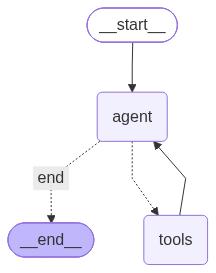

In [36]:
# Add conditional edge from agent
workflow.add_conditional_edges(
    "agent",
    should_continue,
    {
        "tools": "tools",
        "end": END
    }
)
# Add edge from tools back to agent
workflow.add_edge("tools", "agent")
graph = workflow.compile()
logger.info("✅ Enhanced agent created successfully\n")
display(Image(graph.get_graph().draw_mermaid_png()))

Tester l'application Agentic RAG

In [37]:
# Installer les dépendances et Ollama manuellement (sans install.sh)
!apt-get update -qy
!apt-get install -qy zstd

# Télécharger et extraire le binaire Ollama directement
!curl -fSL https://github.com/ollama/ollama/releases/download/v0.33.2/ollama-linux-amd64.tar.zst | tar --zstd -x -C /usr/local

# Vérifier que le binaire existe
!which ollama
!ollama --version

Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Hit:6 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Get:7 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Hit:8 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:9 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease
Hit:10 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Get:11 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 Packages [2,173 kB]
Get:12 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 Packages [1,742 kB]
Fetched 4,041 kB in 3s (1,231 kB/s)
Reading package lists...
W: Skipping acquire of configured file 'main/source/Sources' as re

In [6]:
!ollama pull llama3.1:8b

In [38]:
import subprocess, time, os

# Tuer une éventuelle instance zombie
!pkill -f "ollama serve" 2>/dev/null || true

# Démarrer le serveur en arrière-plan (nohup pour survivre à la fin de la cellule)
os.environ['OLLAMA_HOST'] = '0.0.0.0:11434'
subprocess.Popen(
    ['nohup', 'ollama', 'serve'],
    stdout=open('/tmp/ollama.log', 'w'),
    stderr=open('/tmp/ollama_error.log', 'w'),
    preexec_fn=os.setsid  # détache complètement le processus
)

# Attendre et vérifier que le serveur répond
time.sleep(5)
!curl -s http://localhost:11434/api/tags

^C
{"models":[{"name":"llama3.1:8b","model":"llama3.1:8b","modified_at":"2026-11-05T16:22:54.879319337Z","size":4920753328,"digest":"46e0c10c039e019119339687c3c1757cc81b9da49709a3b3924863ba87ca666e","details":{"parent_model":"","format":"gguf","family":"llama","families":["llama"],"parameter_size":"8.0B","quantization_level":"Q4_K_M","context_length":131072,"embedding_length":4096},"capabilities":["completion","tools"]}]}

In [39]:
print("="*80)
print("TEST 5: Enhanced Agent with RAG - AI Research Activity Check")
print("="*80 + "\n")
query = "Provide a comprehensive investment analysis for NVIDIA (NVDA) and Google including their AI research initiatives"
print(f"Query: {query}\n")
print("-"*80 + "\n")
result = graph.invoke(
    {"messages": [HumanMessage(content=query)]}
)
print("\n🤖 ENHANCED AGENT RESPONSE (with RAG):")
print("="*80)
print(display(Markdown(result["messages"][-1].content)))
print("\n" + "="*80)
print("\n✅ Notice: The agent now includes:")
print(" • AI research projects from private analyst reports")
print(" • Specific AI initiative details")
print(" • Integration of financial + AI research data")
print(" • Comprehensive investment recommendation")

TEST 5: Enhanced Agent with RAG - AI Research Activity Check

Query: Provide a comprehensive investment analysis for NVIDIA (NVDA) and Google including their AI research initiatives

--------------------------------------------------------------------------------


🤖 ENHANCED AGENT RESPONSE (with RAG):


The provided text appears to be a shareholder proposal and a response from the board of directors of Amazon, addressing the company's sustainability efforts and climate goals. The proposal and response cover various topics, including:

1. **Climate Change and Sustainability**: The proposal requests a report on Amazon's efforts to reduce its carbon footprint, including its use of renewable energy, energy efficiency, and waste reduction. The board's response highlights the company's progress in reducing its carbon intensity and its commitment to sustainability.
2. **Data Center Innovation and Efficiency**: The proposal asks for a report on Amazon's data center operations, including its use of renewable energy and energy efficiency measures. The board's response notes the company's efforts to improve data center efficiency, including the development of new technologies and innovations.
3. **Water and Other Natural Resources**: The proposal requests a report on Amazon's water usage and conservation efforts. The board's response highlights the company's goal of being "water positive" by 2030 and its efforts to reduce water usage through efficiency measures and sustainable sources.
4. **Circular Economy and Avoiding and Managing Waste**: The proposal asks for a report on Amazon's efforts to reduce waste and promote a circular economy. The board's response notes the company's initiatives to minimize waste, increase recycling, and provide options for customers to keep items in use longer.
5. **Responsible AI**: The proposal requests a report on Amazon's efforts to develop and use AI responsibly. The board's response highlights the company's commitment to responsible AI, including its eight core priorities and its collaboration with other companies and organizations to develop safe and trustworthy AI.
6. **Investing in Our Communities**: The proposal asks for a report on Amazon's community investments, including its support for disaster relief efforts, education, and affordable housing. The board's response notes the company's donations and deliveries of relief items to support communities impacted by disasters.

The board's response to the proposal emphasizes Amazon's commitment to sustainability and its progress in reducing its carbon footprint. The company highlights its efforts to improve data center efficiency, reduce water usage, and promote a circular economy. The board also notes its commitment to responsible AI and its investments in communities.

None


✅ Notice: The agent now includes:
 • AI research projects from private analyst reports
 • Specific AI initiative details
 • Integration of financial + AI research data
 • Comprehensive investment recommendation
